<p class="hz-kicker">Week 1 · Self-paced lab</p>

# First look at Altamar

The management team wants a first briefing on its 6,060 bookings: how each hotel and each kind of guest behaves, and how far the data can be trusted. In this lab you adjust ready-made code, predict what it will say, and write down what a manager should take from it.

<ul class="hz-lesson-meta"><li>≈ 2 hours</li><li>5 tasks</li><li>Runs in your browser</li><li>Graded quiz</li></ul>

**Recap of the live session**

- A notebook runs cells **in the order you run them**, and its memory keeps results, not cells. Before sharing, **Restart and run all**.
- Python names values (`adr = 180.5`), groups them in lists and dictionaries, and packages rules (`if`) and calculations (`def`) so they can be reused for any booking.
- pandas applies one line to a whole column: `df["canceled"].mean()` is the cancellation rate of all 6,060 bookings.

**How this lab works:** cells marked ✏️ have settings in CAPITALS. Change them, run the cell, answer the question, then open *Show the answer* to check.

Run this cell first. It loads the tools, reads the booking file into `df`, and prepares a small summary table we use in task 3. You don't need to read it.

In [1]:
# Setup: run this cell first. You don't need to read it.
import pandas as pd
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
df = pd.read_csv(DATA + "altamar_bookings.csv")
pd.set_option("display.max_columns", 25)

def summary(table, by):
    """Bookings, average rate (USD) and % cancelled for each group of `by`."""
    out = table.groupby(by).agg(bookings=("adr", "size"), avg_rate_usd=("adr", "mean"), pct_cancelled=("canceled", "mean"))
    out["avg_rate_usd"] = out["avg_rate_usd"].round(1)
    out["pct_cancelled"] = (out["pct_cancelled"] * 100).round(1)
    return out.sort_values("bookings", ascending=False)

print(f"Ready: {len(df):,} bookings loaded.")

Ready: 6,060 bookings loaded.


## <span class="hz-step-n">01</span> Predict before you run

Reading code well means knowing what it will say **before** you run it. Here are the two tools from the live session: Altamar's revenue function and operations' rule of thumb for cancellation risk. If you need a refresher, play with them first.

<div class="hz-widget" data-widget="function-machine">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Lab/">open this session on the course website</a> to use it.</p>
</div>

<div class="hz-widget" data-widget="if-flow">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Lab/">open this session on the course website</a> to use it.</p>
</div>

This cell defines both tools as functions. It prints nothing: it only teaches Python two new words, `stay_revenue` and `cancellation_risk`.

In [2]:
def stay_revenue(adr, nights, discount=0):
    """Room revenue of one stay, after an optional discount (0.10 = 10% off)."""
    total = adr * nights
    if discount > 0:
        total = total * (1 - discount)
    return round(total, 2)

def cancellation_risk(channel, lead_time_days):
    """Operations' rule of thumb from the live session."""
    if channel == "Online travel agency" and lead_time_days > 90:
        return "high"
    elif channel == "Online travel agency" or lead_time_days > 90:
        return "watch"
    return "low"

✏️ One booking, described by its settings. For each change below, **write your prediction first**, then run.

In [3]:
# ✏️ Change these settings. Predict first, then run.
HOTEL = "Viña del Mar"
CHANNEL = "Online travel agency"     # or "Direct", "Corporate", "Travel agent"
LEAD_TIME_DAYS = 120
ADR = 180.5
NIGHTS = 3
DISCOUNT = 0                         # 0.10 means 10% off

revenue = stay_revenue(ADR, NIGHTS, DISCOUNT)
risk = cancellation_risk(CHANNEL, LEAD_TIME_DAYS)
print(f"{HOTEL}: {NIGHTS} nights at USD {ADR} -> USD {revenue:,.2f} of room revenue")
print(f"Booked via {CHANNEL}, {LEAD_TIME_DAYS} days ahead -> cancellation risk: {risk}")

Viña del Mar: 3 nights at USD 180.5 -> USD 541.50 of room revenue
Booked via Online travel agency, 120 days ahead -> cancellation risk: high


**Questions.** (a) Set `NIGHTS = 6`. Does revenue exactly double? (b) Set `DISCOUNT = 0.10`, then `0.20`. How many dollars does each step cost? (c) Set `LEAD_TIME_DAYS = 90`. Which risk, and why? (d) Put `DISCOUNT` back to 0 and set `CHANNEL = "online travel agency"` (lower case). What does the rule say now, and why should that worry a manager?

<details><summary>Show the answer</summary>
<p>(a) Yes: 6 nights give USD 1,083.00, twice 541.50; revenue grows in proportion to nights. (b) Each 10 points of discount costs 10% of the full price, USD 108.30 on 6 nights (54.15 on 3 nights): 974.70, then 866.40. (c) <code>90 &gt; 90</code> is False, so the lead-time test fails; an online agency booking still gets <code>watch</code>. Rules have exact edges: 90 is not “more than 90”. (d) <code>watch</code> instead of <code>high</code>: to Python, a differently spelled channel is a different channel. The real file has four spellings of the online agency channel, so a rule like this would silently miss bookings.</p>
</details>

✏️ One more prediction: two stays with the same revenue? Predict both numbers, run, then try your own pair.

In [4]:
# ✏️ Change these settings
STAY_A = stay_revenue(200.0, 2)
STAY_B = stay_revenue(100.0, 4)

print("Stay A:", STAY_A, "| Stay B:", STAY_B)
print("Same revenue?", STAY_A == STAY_B)

Stay A: 400.0 | Stay B: 400.0
Same revenue? True


**Question.** Both stays bring USD 400. From a hotel manager's point of view, are they equally good? What does the function not see?

<details><summary>Show the answer</summary>
<p>Same room revenue, different business. Stay B occupies the room for four nights, so it uses more capacity (and more cleaning, breakfasts, laundry), but it also fills nights that might stay empty. Stay A earns twice the rate per night, which matters on a high-demand night when the room could be sold again. The function only multiplies; judging the stay needs occupancy and demand, which is exactly why Altamar wants to predict rates.</p>
</details>

## <span class="hz-step-n">02</span> One hotel at a time

✏️ The general manager wants a three-line briefing per hotel. `df[df["hotel"] == HOTEL]` keeps only the rows of one hotel; the three lines compare it with the whole group. Run it for each of the three hotels.

In [5]:
# ✏️ Change this setting: "Santiago", "Viña del Mar" or "Puerto Varas"
HOTEL = "Puerto Varas"

one = df[df["hotel"] == HOTEL]
print(f"{HOTEL}: {len(one):,} bookings ({len(one) / len(df):.0%} of the file)")
print(f"Average rate: USD {one['adr'].mean():.1f} a night (group: USD {df['adr'].mean():.1f})")
print(f"Cancelled: {one['canceled'].mean():.1%} of bookings (group: {df['canceled'].mean():.1%})")

Puerto Varas: 1,439 bookings (24% of the file)
Average rate: USD 158.0 a night (group: USD 128.2)
Cancelled: 37.5% of bookings (group: 33.7%)


**Questions.** Which hotel charges the most per night, and which cancels the most? Then set `HOTEL = "Pto. Varas"`. What do you get, and what does it mean for the Puerto Varas numbers you just read?

<details><summary>Show the answer</summary>
<p>Puerto Varas charges the most (about USD 158 a night, against 128 for the group) and Santiago the least (about USD 100). Viña del Mar cancels the most (about 41%), Santiago the least (about 26%), with Puerto Varas in between (about 37%). <code>"Pto. Varas"</code> returns 74 more Puerto Varas bookings that the filter above left out, because the label is spelled differently. Every hotel has such stray labels, so all three briefings are slightly off until the labels are fixed in week 2.</p>
</details>

## <span class="hz-step-n">03</span> Compare guests and channels

✏️ Hotels compare different kinds of business: business travellers against leisure guests, bookings through online agencies against direct ones. `summary(df, COLUMN)` gives, for each group of a column, its bookings, its average rate and its share cancelled.

In [6]:
# ✏️ Change this setting: "customer_type", "channel", "room_type" or "deposit"
COLUMN = "customer_type"

summary(df, COLUMN)

,bookings,avg_rate_usd,pct_cancelled
customer_type,,,
Leisure,3635,140.5,39.9
Business,1642,106.1,15.9
Group,783,117.6,42.4


The same comparison as a chart: the share cancelled in each group of `COLUMN`, from lowest to highest.

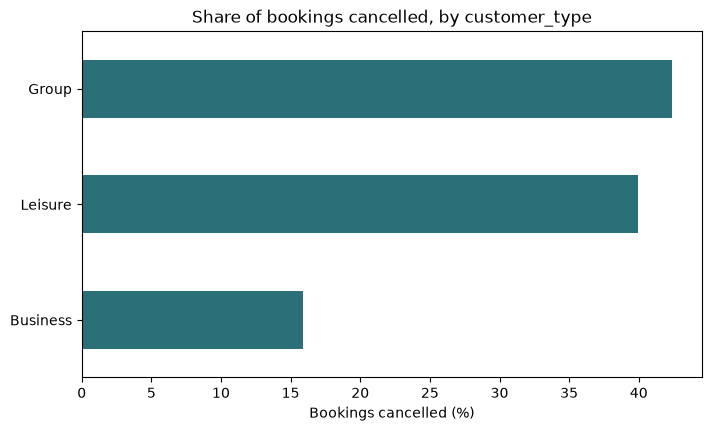

In [7]:
pct = df.groupby(COLUMN)["canceled"].mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
pct.plot.barh(ax=ax, color="#2b6f78")
ax.set_title(f"Share of bookings cancelled, by {COLUMN}")
ax.set_xlabel("Bookings cancelled (%)")
ax.set_ylabel("")
plt.show()

**Questions.** Run it for `customer_type`, then `channel`, then `deposit`. Which group cancels least, and which most? Pick one finding and say what a manager could do with it.

<details><summary>Show the answer</summary>
<p><strong>Customer type:</strong> business guests cancel about 16% of the time, leisure about 40%, groups about 42%; leisure guests pay the most (about USD 141). <strong>Channel:</strong> corporate bookings cancel least (about 16%), online agency bookings most (about 42% under the main label), and the chart shows four spellings of the online agency. <strong>Deposit:</strong> non-refundable bookings cancel about 19%, against about 37% with no deposit. A manager could, for example, ask for a non-refundable deposit on leisure online-agency bookings in peak season, or oversell more where cancellations are frequent. These are differences, not causes yet: weeks 4 to 6 test them properly.</p>
</details>

## <span class="hz-step-n">04</span> Spot three data problems

A briefing is only as good as the data under it. The next two cells look for problems: first the summary of every numeric column (keep an eye on `count`, `min` and `max`), then missing values, duplicate rows and the hotel labels.

In [8]:
df.describe().round(1).T[["count", "mean", "min", "50%", "max"]]

,count,mean,min,50%,max
lead_time_days,6060.0,48.8,-152.0,30.0,424.0
nights,6060.0,3.9,1.0,3.0,8.0
weekend_nights,6060.0,1.7,0.0,2.0,4.0
adults,6060.0,1.9,0.0,2.0,4.0
children,5999.0,0.4,0.0,0.0,3.0
repeat_guest,6060.0,0.1,0.0,0.0,1.0
previous_cancellations,6060.0,0.2,0.0,0.0,3.0
special_requests,6060.0,0.7,0.0,0.0,6.0
parking,6060.0,0.3,0.0,0.0,1.0
adr,6060.0,128.2,0.0,113.4,1668.1


`isna()` marks missing values, `duplicated()` marks rows that are exact copies of an earlier row, and `unique()` lists the different labels of a column.

In [9]:
missing = df.isna().sum()
print("Missing values:", missing[missing > 0].to_dict())
print("Exact duplicate rows:", df.duplicated().sum())
print("Hotel labels:", sorted(df["hotel"].unique()))
print("Channel labels:", sorted(df["channel"].unique()))

Missing values: {'children': 61, 'country': 184}
Exact duplicate rows: 60
Hotel labels: ['Pto. Varas', 'Puerto Varas', 'SANTIAGO', 'Santiago', 'VIÑA DEL MAR', 'Vina del Mar', 'Viña del Mar']
Channel labels: ['Corporate', 'Direct', 'OTA', 'Online Travel Agency', 'Online travel agency', 'Travel agent', 'online travel agency']


✏️ **Write your three problems here** (in Colab, double-click the cell to edit it). For each one: what you saw, and why it matters for a decision.

1. **Problem:** … **Why it matters:** …
2. **Problem:** … **Why it matters:** …
3. **Problem:** … **Why it matters:** …

<details><summary>Show the answer</summary>
<p>Any three of these:</p>
<ul>
<li><strong>Hotels and channels with several spellings</strong> (<code>SANTIAGO</code>, <code>Pto. Varas</code>, <code>OTA</code>…): every count and rate by hotel or channel is split and slightly wrong.</li>
<li><strong>60 duplicate rows</strong>: the same booking counted twice inflates demand and revenue.</li>
<li><strong>12 rates of 0</strong> (complimentary rooms) and <strong>6 rates above USD 1,000</strong> (an extra zero): both distort the average rate, the base of every pricing decision.</li>
<li><strong>10 negative lead times</strong>: impossible dates, which would mislead any analysis of how far ahead guests book.</li>
<li><strong>8 bookings for 0 adults</strong>: probably input errors.</li>
<li><strong>Missing <code>children</code> (61) and <code>country</code> (184)</strong>: a decision about family rooms or foreign markets would rest on incomplete data.</li>
</ul>
</details>

## <span class="hz-step-n">05</span> Altamar's two questions, in your words

The whole module answers two management questions. Rewrite them as you would present them to Altamar's general manager: the decision, who takes it, how often, and **which column of the file holds the answer** (and so whether it is regression or classification).

✏️ **Your version** (double-click to edit in Colab):

**Revenue question:** …
**Who decides, and how often:** …
**Column that answers it:** … → regression or classification? …

**Operations question:** …
**Who decides, and how often:** …
**Column that answers it:** … → regression or classification? …

<details><summary>Show the answer</summary>
<p>One good version: <strong>Revenue:</strong> <em>For each new booking, what nightly rate can we charge given the hotel, season, room and how far ahead the guest books?</em> The revenue manager, every morning, for each hotel and room type. Column <code>adr</code>, a number: <strong>regression</strong>.</p>
<p><strong>Operations:</strong> <em>Which of tonight's bookings are likely to cancel, so how many extra rooms can each hotel safely sell?</em> The operations manager of each hotel, every day. Column <code>canceled</code>, yes or no: <strong>classification</strong>.</p>
<p>The test of a good question: someone could act on the answer tomorrow, and you could check afterwards whether it was right.</p>
</details>

## Graded quiz

Five questions on this week's ideas. They count for **5% of the module grade**, and **only your first submission counts**, so finish the lab before you start. Use the name and email you are registered with in the program.

<div class="hz-widget" data-widget="graded-quiz">
<script type="application/json">{"id": "session-1", "title": "Week 1 quiz", "questions": [{"q": "The revenue manager wants to estimate the nightly rate a new booking can be charged. Which setup fits?", "options": ["Classification, predicting <code>hotel</code>", "Regression, predicting <code>adr</code>", "Regression, predicting <code>booking_id</code>", "Classification, predicting <code>canceled</code>"]}, {"q": "<code>describe()</code> shows that <code>lead_time_days</code> has a minimum of −152. What is the best reaction?", "options": ["It shows guests who booked 152 days late, so the hotel was full", "Nothing: one value cannot change any result", "Treat it as a data problem: a booking cannot be made after arrival, so those rows need checking before any analysis", "Delete the whole <code>lead_time_days</code> column"]}, {"q": "You filter <code>df[df[\"hotel\"] == \"Santiago\"]</code> and get 2,378 bookings, but <code>value_counts()</code> also lists 110 bookings as <code>SANTIAGO</code>. What does this mean for the Santiago cancellation rate you computed?", "options": ["It is exact: SANTIAGO is a different hotel", "It is doubled, because those bookings are counted twice", "It leaves out 110 Santiago bookings, so it may be off until the labels are unified", "Python ignores upper and lower case, so nothing changes"]}, {"q": "A colleague's notebook shows a different average rate each time they open it, because they run the cells in a different order. What should they do before sharing it?", "options": ["Copy the numbers into a slide by hand", "Run the last cell twice to be sure", "Delete the cells that print results", "Restart the notebook and run all cells from top to bottom, then check the results"]}, {"q": "A booking had a 10% discount, but a colleague computed its revenue with <code>stay_revenue(120.0, 5)</code>, where the function is <code>stay_revenue(adr, nights, discount=0)</code>. What is wrong?", "options": ["The result understates revenue, because 5 nights earn a long-stay bonus", "The function fails with an error because discount is missing", "The result, USD 600, overstates revenue by USD 60: discount took its default, 0", "Nothing: the function applies discounts automatically"]}]}</script>
</div>